# Household Energy Analysis — a Methods Demonstration

Predict consumption from household attributes, classify **relative energy intensity**, and explore consumption groups.
The bundled CSV's original publisher, collection method, measurement period, area units, energy units, and real-versus-synthetic status are **unverified**. No generator or source citation is provided in this repository. Do not present these results as measured real-world energy efficiency or causal effects. Numeric errors below use the CSV's `units` scale; kWh cannot be confirmed.

Every executable cell has a preceding explanation of its purpose and assumptions. See `CELL_GUIDE.md` for interview questions. Reading a guide does not establish understanding: rerun, change an assumption, and explain the resulting change yourself.


## 1. Setup
Fix random seeds so splits and models are repeatable. Import metrics explicitly; leave warnings visible. Record library versions with the results because numerical results can vary across versions.


In [1]:
import json
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
    silhouette_score)
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

SEED = 42
versions = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit-learn': sklearn.__version__}
print(versions)


{'python': '3.13.11', 'numpy': '2.5.5', 'pandas': '3.1.1', 'scikit-learn': '1.9.0'}


## 2. Load and validate the raw data
Keep the raw CSV unchanged for traceability. `source_row` is the original CSV line number, not a household identifier. Colab accepts one uploaded CSV; local execution reads the bundled file. Check the expected schema instead of silently accepting incompatible data.


In [2]:
csv_path = Path('data/household_energy_unit_data.csv')
if not csv_path.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError('Upload exactly one household CSV.')
        csv_path = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError('Run from the repository root; expected data/household_energy_unit_data.csv')
features = ['num_rooms', 'num_people', 'housearea', 'is_ac', 'is_tv',
            'is_flat', 'num_children', 'is_urban']
raw = pd.read_csv(csv_path)
assert set(raw.columns) == set(features + ['units']), 'Unexpected CSV schema'
raw.index = pd.Index(np.arange(2, len(raw) + 2), name='source_row')
print('Raw shape:', raw.shape)
display(raw.head())
display(raw.describe())


Raw shape: (1000, 9)


,num_rooms,num_people,housearea,is_ac,is_tv,is_flat,num_children,is_urban,units
source_row,,,,,,,,,
2,3,3,742.57,1,1,1,2,0,134.731117
3,1,5,952.99,0,1,0,1,1,125.315527
4,3,1,761.44,1,1,1,0,0,123.047874
5,0,5,861.32,1,1,0,0,0,80.046162
6,1,8,731.61,0,1,0,2,1,128.429094


,num_rooms,num_people,housearea,is_ac,is_tv,is_flat,num_children,is_urban,units
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,1.962000,4.897000,794.703420,0.376000,0.798000,0.477000,1.078000,0.608000,123.597217
std,1.030348,2.007591,147.771736,0.484622,0.401693,0.499721,0.934232,0.488441,27.106187
min,-1.000000,-1.000000,244.400000,0.000000,0.000000,0.000000,0.000000,0.000000,21.118233
25%,1.000000,4.000000,691.037500,0.000000,1.000000,0.000000,0.000000,0.000000,109.157723
50%,2.000000,5.000000,789.970000,0.000000,1.000000,0.000000,1.000000,1.000000,126.332934
75%,3.000000,6.000000,892.955000,1.000000,1.000000,1.000000,2.000000,1.000000,141.820476
max,5.000000,11.000000,1189.120000,1.000000,1.000000,1.000000,4.000000,1.000000,204.189253


## 3. Explicit data-quality rules, before ratios or splitting
Drop rows with missing/nonfinite values, negative or fractional counts, zero occupants or area, negative consumption, or nonbinary flags. Rooms and children may be zero; occupants must be positive to define per-person use. Report overlapping rule counts and unique exclusions separately. No imputation is needed for this CSV; dropping avoids inventing counts for invalid records.

Remove exact duplicates to avoid identical records crossing the split. Do **not** discard valid high/low consumption with IQR filtering: the old all-column filter removed valid binary categories and selected on the target. Keep plausible extremes and evaluate errors on them. These rules encode assumptions, not proof of data authenticity.


In [3]:
numeric = raw.apply(pd.to_numeric, errors='coerce')
counts = ['num_rooms', 'num_people', 'num_children']
flags = ['is_ac', 'is_tv', 'is_flat', 'is_urban']
rules = pd.DataFrame({
    'missing_or_nonfinite': ~np.isfinite(numeric).all(axis=1),
    'negative_count': (numeric[counts] < 0).any(axis=1),
    'fractional_count': (numeric[counts].mod(1) != 0).any(axis=1),
    'zero_occupants': numeric['num_people'].eq(0),
    'nonpositive_area': numeric['housearea'].le(0),
    'negative_consumption': numeric['units'].lt(0),
    'invalid_binary_flag': ~numeric[flags].isin([0, 1]).all(axis=1),
}, index=raw.index)
invalid = rules.any(axis=1)
valid = numeric.loc[~invalid].copy()
duplicate = valid.duplicated()
df = valid.loc[~duplicate].copy()
quality = {'raw_rows': len(raw), 'rule_counts': rules.sum().astype(int).to_dict(),
           'invalid_rows_dropped': int(invalid.sum()),
           'duplicate_rows_dropped': int(duplicate.sum()), 'clean_rows': len(df)}
print(json.dumps(quality, indent=2))
print('Excluded CSV lines:', raw.index[invalid].tolist())
display(raw.loc[invalid])
assert (df[counts] >= 0).all().all()
assert (df['num_people'] > 0).all() and (df['housearea'] > 0).all()
assert np.isfinite(df).all().all() and not df.duplicated().any()
assert len(raw) == len(df) + invalid.sum() + duplicate.sum()
df['Energy_per_Person'] = df['units'] / df['num_people']
df['Energy_per_Area'] = df['units'] / df['housearea']


{
  "raw_rows": 1000,
  "rule_counts": {
    "missing_or_nonfinite": 0,
    "negative_count": 9,
    "fractional_count": 0,
    "zero_occupants": 13,
    "nonpositive_area": 0,
    "negative_consumption": 0,
    "invalid_binary_flag": 0
  },
  "invalid_rows_dropped": 22,
  "duplicate_rows_dropped": 0,
  "clean_rows": 978
}
Excluded CSV lines: [46, 62, 92, 123, 127, 172, 183, 202, 430, 484, 621, 634, 639, 660, 770, 835, 838, 849, 941, 947, 967, 997]


,num_rooms,num_people,housearea,is_ac,is_tv,is_flat,num_children,is_urban,units
source_row,,,,,,,,,
46,2,0,1042.81,0,0,1,0,0,57.427931
62,1,0,878.69,0,1,1,2,1,148.772627
92,-1,5,697.17,0,1,1,2,1,148.258391
123,-1,2,638.39,0,1,0,2,1,130.570766
127,2,0,549.85,0,0,0,2,1,122.572599
172,4,-1,1058.32,1,0,0,4,0,143.975525
183,-1,8,801.48,1,1,0,2,1,166.041480
202,3,0,618.91,1,1,0,0,1,134.753975
430,2,0,797.67,1,1,1,2,0,177.434792


## 4. Explore the cleaned distribution
Histograms expose range and skew; the scatter shows associations. Ratios contain the target and are for description, label construction, and clustering only. Never include them as predictive features. This full-data EDA is descriptive; model choices below are fixed in advance rather than tuned from these plots.


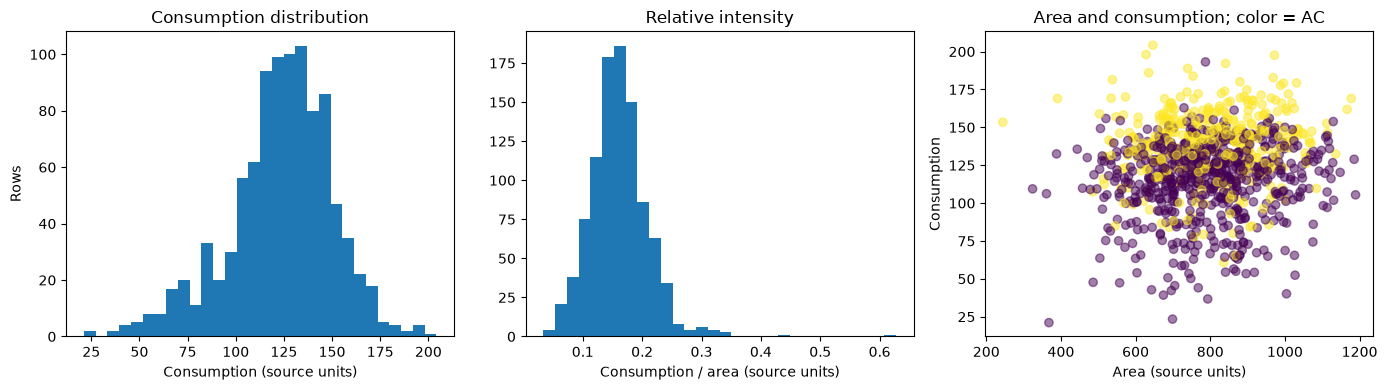

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(df['units'], bins=30)
axes[0].set(xlabel='Consumption (source units)', ylabel='Rows', title='Consumption distribution')
axes[1].hist(df['Energy_per_Area'], bins=30)
axes[1].set(xlabel='Consumption / area (source units)', title='Relative intensity')
axes[2].scatter(df['housearea'], df['units'], c=df['is_ac'], alpha=0.5)
axes[2].set(xlabel='Area (source units)', ylabel='Consumption', title='Area and consumption; color = AC')
plt.tight_layout()
plt.show()


## 5. Hold out households before learning any thresholds
Use one seeded 80/20 split for both tasks. A random split makes an independent-row assumption; no household/time/group identifiers exist to validate it. Derive the median intensity from **training rows only** and freeze it for the test set. Do not stratify on labels derived from the full dataset. Label 1 means lower relative intensity; it is a proxy, not a verified efficiency rating.


In [5]:
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=SEED)
X_train, X_test = df.loc[train_idx, features], df.loc[test_idx, features]
y_train, y_test = df.loc[train_idx, 'units'], df.loc[test_idx, 'units']
threshold = df.loc[train_idx, 'Energy_per_Area'].median()
yc_train = (df.loc[train_idx, 'Energy_per_Area'] <= threshold).astype(int)
yc_test = (df.loc[test_idx, 'Energy_per_Area'] <= threshold).astype(int)
assert set(train_idx).isdisjoint(test_idx)
assert not set(features) & {'units', 'Energy_per_Person', 'Energy_per_Area'}
print(f'Train: {len(train_idx)}, test: {len(test_idx)}; training median intensity: {threshold:.6f}')
print('Training label proportions:', yc_train.value_counts(normalize=True).sort_index().to_dict())
print('Test label proportions:', yc_test.value_counts(normalize=True).sort_index().to_dict())


Train: 782, test: 196; training median intensity: 0.158948
Training label proportions: {0: 0.5, 1: 0.5}
Test label proportions: {0: 0.4744897959183674, 1: 0.5255102040816326}


## 6. Regression: select using training-only cross-validation
Compare a linear model with a 200-tree random forest. Five shuffled training folds select the lower mean RMSE; the test set is reserved for reporting. Linear regression captures additive effects; a forest can capture nonlinear interactions. Neither establishes causality. No scaling is required for these models.


In [6]:
regressors = {'Linear Regression': LinearRegression(),
              'Random Forest': RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=1)}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name, model in regressors.items():
    fold_rmse = np.sqrt(-cross_val_score(model, X_train, y_train, cv=cv,
                                       scoring='neg_mean_squared_error'))
    cv_rows.append({'model': name, 'cv_rmse_mean': fold_rmse.mean(),
                    'cv_rmse_std': fold_rmse.std()})
cv_results = pd.DataFrame(cv_rows).set_index('model')
best_reg_name = cv_results['cv_rmse_mean'].idxmin()
display(cv_results)
print('Selected before looking at test metrics:', best_reg_name)


,cv_rmse_mean,cv_rmse_std
model,,
Linear Regression,13.404565,0.842329
Random Forest,13.913699,1.076284


Selected before looking at test metrics: Linear Regression


## 7. Regression evaluation against predicting the training mean
Fit a `DummyRegressor` on training targets, then evaluate all models on the same held-out rows. MAE is typical absolute error; RMSE weights large misses more heavily; R² compares squared error to variation in the test targets and can be negative. The dummy's R² need not be exactly zero because its constant is the training mean, not the test mean.


In [7]:
baseline_reg = DummyRegressor(strategy='mean').fit(X_train, y_train)
reg_predictions = {'Training-mean baseline': baseline_reg.predict(X_test)}
for name, model in regressors.items():
    model.fit(X_train, y_train)
    reg_predictions[name] = model.predict(X_test)
def reg_metrics(actual, predicted):
    return {'mae': float(mean_absolute_error(actual, predicted)),
            'rmse': float(np.sqrt(mean_squared_error(actual, predicted))),
            'r2': float(r2_score(actual, predicted))}
reg_results = pd.DataFrame({name: reg_metrics(y_test, pred)
                           for name, pred in reg_predictions.items()}).T
display(reg_results)
best_reg = regressors[best_reg_name]
y_pred = reg_predictions[best_reg_name]


,mae,rmse,r2
Training-mean baseline,20.708055,26.495562,-0.011413
Linear Regression,10.271702,13.575753,0.734472
Random Forest,10.244750,13.025383,0.755565


## 8. Classification baseline, precision, recall, F1, and confusion matrix
Fit the majority class using **training** labels, not the test majority. Evaluate it and the forest on identical held-out rows. Accuracy measures all correct predictions; precision measures how often a predicted class is correct; recall measures how many actual members of that class are found; F1 balances precision and recall. Report both classes plus macro/weighted averages. A constant predictor can have high accuracy under imbalance while missing a class entirely. Trees do not need scaling.



Majority-class baseline: accuracy=0.4745


,precision,recall,f1-score,support
Higher intensity (0),0.474490,1.00000,0.643599,93.00000
Lower intensity (1),0.000000,0.00000,0.000000,103.00000
accuracy,0.474490,0.47449,0.474490,0.47449
macro avg,0.237245,0.50000,0.321799,196.00000
weighted avg,0.225141,0.47449,0.305381,196.00000


Confusion matrix: rows=actual, columns=predicted; order=[0, 1]
[[ 93   0]
 [103   0]]

Random Forest: accuracy=0.8622


,precision,recall,f1-score,support
Higher intensity (0),0.851064,0.860215,0.855615,93.000000
Lower intensity (1),0.872549,0.864078,0.868293,103.000000
accuracy,0.862245,0.862245,0.862245,0.862245
macro avg,0.861806,0.862146,0.861954,196.000000
weighted avg,0.862355,0.862245,0.862277,196.000000


Confusion matrix: rows=actual, columns=predicted; order=[0, 1]
[[80 13]
 [14 89]]


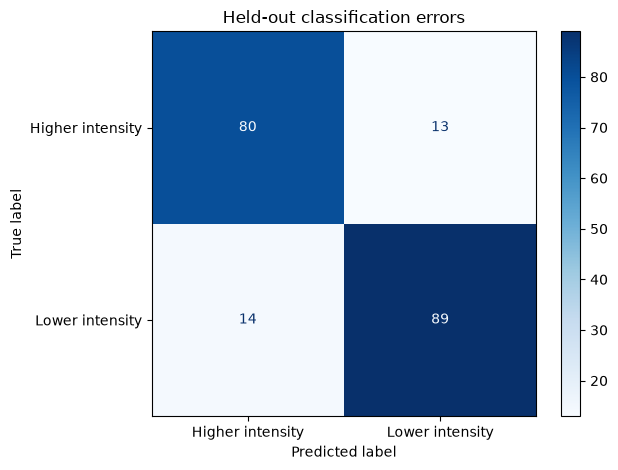

Accuracy lift (percentage points): 38.775510204081634


In [8]:
baseline_class = DummyClassifier(strategy='most_frequent').fit(X_train, yc_train)
classifier = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1)
classifier.fit(X_train, yc_train)
class_predictions = {'Majority-class baseline': baseline_class.predict(X_test),
                     'Random Forest': classifier.predict(X_test)}
class_reports = {}
class_accuracy = {}
for name, predicted in class_predictions.items():
    class_accuracy[name] = float(accuracy_score(yc_test, predicted))
    class_reports[name] = classification_report(yc_test, predicted, labels=[0, 1],
        target_names=['Higher intensity (0)', 'Lower intensity (1)'],
        output_dict=True, zero_division=0)
    print(f'\n{name}: accuracy={class_accuracy[name]:.4f}')
    display(pd.DataFrame(class_reports[name]).T)
    print('Confusion matrix: rows=actual, columns=predicted; order=[0, 1]')
    print(confusion_matrix(yc_test, predicted, labels=[0, 1]))
class_pred = class_predictions['Random Forest']
ConfusionMatrixDisplay.from_predictions(yc_test, class_pred, labels=[0, 1],
    display_labels=['Higher intensity', 'Lower intensity'], cmap='Blues')
plt.title('Held-out classification errors')
plt.tight_layout()
plt.show()
print('Accuracy lift (percentage points):',
      100 * (class_accuracy['Random Forest'] - class_accuracy['Majority-class baseline']))


## 9. Error Analysis & Learnings — residuals and mispredicted households
Residual = actual minus predicted: positive values mean underprediction. Inspect largest held-out errors with CSV row references and summarize MAE/bias by AC and occupant count. Small subgroup counts make comparisons unstable. For classification, show wrong predictions and their distance from the frozen threshold; close calls reveal sensitivity to the proxy definition. These are post-hoc diagnostics, not another tuning set. Any subsequent tuning needs a fresh evaluation split.


Ten largest regression misses (source_row = CSV line):


,num_rooms,num_people,housearea,is_ac,is_tv,is_flat,num_children,is_urban,units,Energy_per_Area,predicted,residual,absolute_error,actual_class,predicted_class,misclassified,distance_to_threshold
source_row,,,,,,,,,,,,,,,,,
898,3,5,646.24,1,1,1,3,0,204.189253,0.315965,160.760012,43.429241,43.429241,0,0,False,0.157017
761,1,4,739.46,1,1,0,3,0,188.857243,0.255399,149.499252,39.357991,39.357991,0,0,False,0.096451
329,2,5,674.53,0,1,0,0,0,39.270378,0.058219,78.039756,-38.769378,38.769378,1,1,False,0.100729
680,2,3,971.81,1,1,1,3,0,197.567959,0.203299,160.492094,37.075865,37.075865,0,0,False,0.044351
418,0,6,686.45,1,1,0,1,0,155.100235,0.225945,119.697870,35.402366,35.402366,0,0,False,0.066998
451,0,5,868.52,0,1,1,0,0,55.036382,0.063368,87.946857,-32.910475,32.910475,1,1,False,0.095580
733,2,7,847.06,1,1,0,1,0,155.091759,0.183094,122.390656,32.701103,32.701103,0,1,True,0.024147
362,1,5,836.06,1,0,0,0,0,60.843203,0.072774,92.966554,-32.123351,32.123351,1,1,False,0.086174
950,1,4,1025.35,1,1,1,1,0,162.364468,0.158350,130.523126,31.841342,31.841342,1,1,False,0.000597


Regression errors by AC status:


,n,mae,bias
is_ac,,,
0,120,8.644263,0.321560
1,76,12.841342,2.840613


,n,mae,bias
occupant_group,,,
1-3,41,9.552211,1.693400
4-6,119,10.394150,0.768712
7+,36,10.686363,2.599104


Misclassified rows nearest the training threshold (up to 10):


,num_rooms,num_people,housearea,is_ac,is_tv,is_flat,num_children,is_urban,units,Energy_per_Area,predicted,residual,absolute_error,actual_class,predicted_class,misclassified,distance_to_threshold,occupant_group
source_row,,,,,,,,,,,,,,,,,,
544,2,4,717.39,1,1,1,1,0,113.751660,0.158563,129.399288,-15.647628,15.647628,1,0,True,0.000384,4-6
986,2,4,721.09,0,1,0,1,0,114.928797,0.159382,92.778527,22.150270,22.150270,0,1,True,0.000434,4-6
165,2,4,771.59,0,1,1,1,1,121.391162,0.157326,129.233894,-7.842732,7.842732,1,0,True,0.001622,4-6
498,1,5,903.23,1,1,0,1,1,141.817955,0.157012,146.909231,-5.091276,5.091276,1,0,True,0.001936,4-6
784,2,6,665.98,0,0,0,0,1,102.785621,0.154337,92.873063,9.912558,9.912558,1,0,True,0.004610,4-6
922,0,7,926.45,1,0,1,2,1,142.845655,0.154186,161.045009,-18.199354,18.199354,1,0,True,0.004762,7+
31,2,7,816.77,0,1,1,1,1,134.048503,0.164120,131.708485,2.340018,2.340018,0,1,True,0.005173,7+
767,2,6,862.32,1,0,0,1,1,141.720740,0.164348,135.865717,5.855023,5.855023,0,1,True,0.005401,4-6
115,1,2,984.48,1,1,1,2,1,151.092275,0.153474,170.288436,-19.196161,19.196161,1,0,True,0.005473,1-3


,n,median_distance
misclassified,,
False,169,0.031420
True,27,0.008949


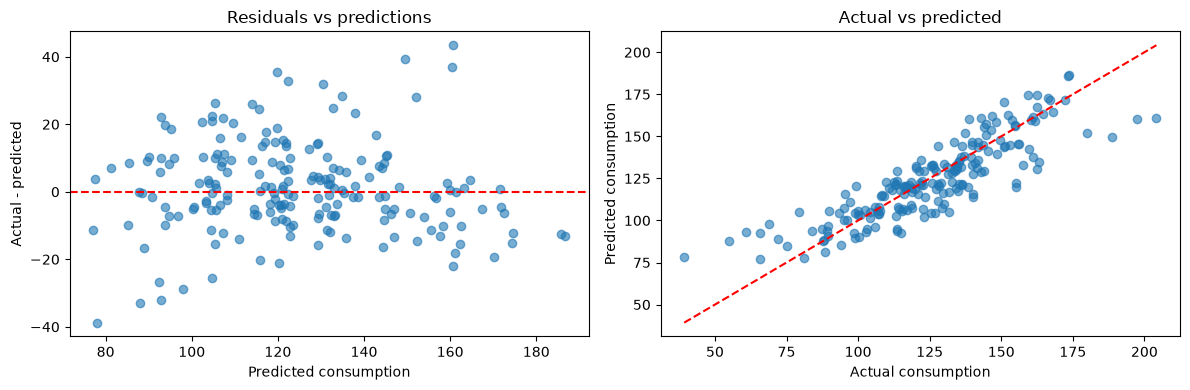

In [9]:
errors = df.loc[test_idx, features + ['units', 'Energy_per_Area']].copy()
errors['predicted'] = y_pred
errors['residual'] = errors['units'] - errors['predicted']
errors['absolute_error'] = errors['residual'].abs()
errors['actual_class'] = yc_test
errors['predicted_class'] = class_pred
errors['misclassified'] = errors['actual_class'] != errors['predicted_class']
errors['distance_to_threshold'] = (errors['Energy_per_Area'] - threshold).abs()
print('Ten largest regression misses (source_row = CSV line):')
display(errors.nlargest(10, 'absolute_error'))
print('Regression errors by AC status:')
ac_errors = errors.groupby('is_ac').agg(n=('residual', 'size'),
    mae=('absolute_error', 'mean'), bias=('residual', 'mean'))
display(ac_errors)
errors['occupant_group'] = pd.cut(errors['num_people'], bins=[0, 3, 6, np.inf],
                                labels=['1-3', '4-6', '7+'])
display(errors.groupby('occupant_group', observed=True).agg(n=('residual', 'size'),
    mae=('absolute_error', 'mean'), bias=('residual', 'mean')))
print('Misclassified rows nearest the training threshold (up to 10):')
display(errors.loc[errors['misclassified']].nsmallest(10, 'distance_to_threshold'))
display(errors.groupby('misclassified').agg(n=('residual', 'size'),
    median_distance=('distance_to_threshold', 'median')))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_pred, errors['residual'], alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set(xlabel='Predicted consumption', ylabel='Actual - predicted', title='Residuals vs predictions')
axes[1].scatter(y_test, y_pred, alpha=0.6)
limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[1].plot(limits, limits, 'r--')
axes[1].set(xlabel='Actual consumption', ylabel='Predicted consumption', title='Actual vs predicted')
plt.tight_layout()
plt.show()


## 10. Feature importance and concrete takeaways
Permutation importance shuffles one held-out feature and measures the score decrease. Use the same method for linear and forest models; raw coefficient sizes mix feature units and are not comparable. Correlated predictors can share or hide importance; repeated shuffles show variability, not confidence intervals. Importance describes predictive association, not intervention effects. Area is also in the label's denominator, so high classification importance can reflect label construction.


In [10]:
reg_perm = permutation_importance(best_reg, X_test, y_test, scoring='neg_mean_absolute_error',
                                 n_repeats=10, random_state=SEED)
class_perm = permutation_importance(classifier, X_test, yc_test, scoring='accuracy',
                                   n_repeats=10, random_state=SEED)
def importance_table(result):
    return pd.DataFrame({'feature': features, 'score_decrease': result.importances_mean,
                         'shuffle_std': result.importances_std}).sort_values('score_decrease', ascending=False)
reg_importance = importance_table(reg_perm)
class_importance = importance_table(class_perm)
print('Regression importance: increase in MAE after shuffling')
display(reg_importance)
print('Classification importance: decrease in accuracy after shuffling')
display(class_importance)
worst = errors.loc[errors['absolute_error'].idxmax()]
worst_group = ac_errors['mae'].idxmax()
wrong = errors.loc[errors['misclassified']]
wrong_distance = float(wrong['distance_to_threshold'].median()) if len(wrong) else None
takeaways = [
    f"The largest held-out regression miss is CSV line {errors['absolute_error'].idxmax()}, "
    f"with absolute error {worst['absolute_error']:.2f} and residual {worst['residual']:.2f}. "
    f"AC={int(worst_group)} has the higher observed subgroup MAE ({ac_errors.loc[worst_group, 'mae']:.2f}, "
    f"n={int(ac_errors.loc[worst_group, 'n'])}). Retain these cases and investigate missing context "
    "such as weather, appliance usage, and measurement duration rather than deleting difficult observations.",
    f"There are {len(wrong)}/{len(errors)} classification mistakes; median distance from the label "
    f"threshold among mistakes is {wrong_distance}. Inspect the correct/wrong distance table above "
    "before claiming threshold ambiguity explains failures. Validate with measured efficiency labels "
    "before using this proxy for decisions.",
    f"Top permutation features are {reg_importance.iloc[0]['feature']} for regression and "
    f"{class_importance.iloc[0]['feature']} for classification. Importance supports predictive explanation "
    "only; the area-based label and unknown provenance prevent causal or real-world efficiency claims."
]
display(Markdown('### Observed learnings\n' + '\n'.join(f'{i+1}. {t}' for i, t in enumerate(takeaways))))


Regression importance: increase in MAE after shuffling


,feature,score_decrease,shuffle_std
6,num_children,8.615732,0.783917
3,is_ac,8.061747,1.133349
7,is_urban,6.531078,0.841301
4,is_tv,1.313096,0.416183
5,is_flat,1.292611,0.226498
1,num_people,0.179974,0.129753
2,housearea,0.048009,0.047344
0,num_rooms,-0.096605,0.024353


Classification importance: decrease in accuracy after shuffling


,feature,score_decrease,shuffle_std
2,housearea,2.127551e-01,0.036653
6,num_children,1.015306e-01,0.022868
3,is_ac,8.571429e-02,0.021862
7,is_urban,7.704082e-02,0.017593
1,num_people,4.081633e-02,0.011409
0,num_rooms,1.683673e-02,0.007233
5,is_flat,1.110223e-17,0.012497
4,is_tv,-1.530612e-03,0.007585


### Observed learnings
1. The largest held-out regression miss is CSV line 898, with absolute error 43.43 and residual 43.43. AC=1 has the higher observed subgroup MAE (12.84, n=76). Retain these cases and investigate missing context such as weather, appliance usage, and measurement duration rather than deleting difficult observations.
2. There are 27/196 classification mistakes; median distance from the label threshold among mistakes is 0.008948617946653442. Inspect the correct/wrong distance table above before claiming threshold ambiguity explains failures. Validate with measured efficiency labels before using this proxy for decisions.
3. Top permutation features are num_children for regression and housearea for classification. Importance supports predictive explanation only; the area-based label and unknown provenance prevent causal or real-world efficiency claims.

## 11. Exploratory clustering
Standardize ratio and size features because K-means uses Euclidean distance. Compare inertia and silhouette for k=2..6; use k=3 as an illustrative profile count, not evidence of three natural household types. This descriptive step uses all cleaned rows and observed consumption, so it is neither a predictive test nor a deployable pre-consumption classifier.


,k,inertia,silhouette
0,2,2936.688792,0.245528
1,3,2364.050672,0.267826
2,4,1945.215876,0.245878
3,5,1696.979135,0.244135
4,6,1542.038738,0.229846


,Energy_per_Person,Energy_per_Area,num_rooms,housearea,units
cluster,,,,,
0,24.357327,0.131214,1.884536,897.335670,117.687201
1,27.143997,0.194818,2.075426,672.332993,129.135488
2,87.159811,0.165292,1.902439,798.430732,129.074195


Cluster sizes: {0: 485, 1: 411, 2: 82}


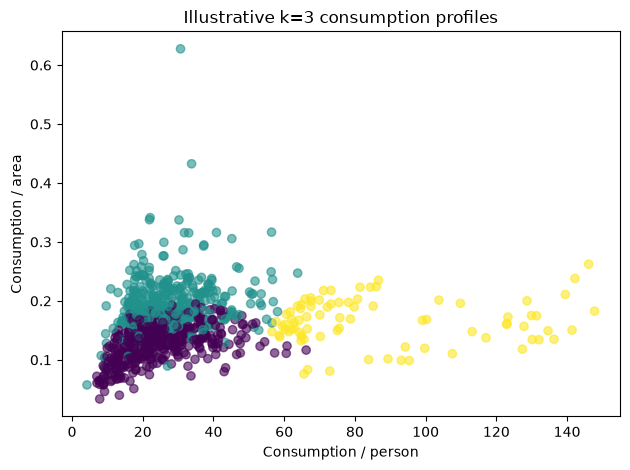

In [11]:
cluster_features = ['Energy_per_Person', 'Energy_per_Area', 'num_rooms', 'housearea']
Z = StandardScaler().fit_transform(df[cluster_features])
cluster_rows = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(Z)
    cluster_rows.append({'k': k, 'inertia': km.inertia_,
                         'silhouette': silhouette_score(Z, km.labels_)})
display(pd.DataFrame(cluster_rows))
clusters = KMeans(n_clusters=3, random_state=SEED, n_init=10).fit_predict(Z)
profiles = df.assign(cluster=clusters).groupby('cluster')[cluster_features + ['units']].mean()
display(profiles)
print('Cluster sizes:', pd.Series(clusters).value_counts().sort_index().to_dict())
plt.scatter(df['Energy_per_Person'], df['Energy_per_Area'], c=clusters, cmap='viridis', alpha=0.6)
plt.xlabel('Consumption / person')
plt.ylabel('Consumption / area')
plt.title('Illustrative k=3 consumption profiles')
plt.tight_layout()
plt.show()


## 12. Reproducible report and checks
Save machine-readable metrics, excluded-row audit, and held-out errors for review. Assertions check alignment, disjoint splits, and baseline definitions. Numbers are computed, not copied from an earlier run. This single split is a demonstration: it does not quantify performance on another region, period, or real dataset.


In [12]:
assert len(y_pred) == len(y_test) == len(class_pred)
assert np.allclose(reg_predictions['Training-mean baseline'], y_train.mean())
assert np.all(class_predictions['Majority-class baseline'] == yc_train.mode().iloc[0])
assert sum(confusion_matrix(yc_test, class_pred, labels=[0, 1]).ravel()) == len(test_idx)
report = {'versions': versions, 'quality': quality, 'train_rows': len(train_idx),
    'test_rows': len(test_idx), 'training_intensity_median': float(threshold),
    'selected_regressor': best_reg_name, 'regression_cv': cv_results.to_dict(orient='index'),
    'regression': reg_results.to_dict(orient='index'), 'classification_accuracy': class_accuracy,
    'classification_reports': class_reports,
    'confusion_matrix_labels_0_1': confusion_matrix(yc_test, class_pred, labels=[0, 1]).tolist(),
    'regression_importance': reg_importance.to_dict(orient='records'),
    'classification_importance': class_importance.to_dict(orient='records'),
    'learnings': takeaways, 'provenance': 'Unverified; methods demonstration only'}
Path('reports').mkdir(exist_ok=True)
Path('reports/metrics.json').write_text(json.dumps(report, indent=2, allow_nan=False) + '\n', encoding='utf-8')
raw.loc[invalid].join(rules.add_prefix('rule_')).to_csv('reports/excluded_rows.csv')
errors.to_csv('reports/held_out_errors.csv')
print(f"Cleaning: {len(raw)} raw -> {len(df)} valid rows; no IQR filtering.")
display(reg_results)
print('Classification accuracy:', class_accuracy)
print('All validation assertions passed. Reports saved in reports/.')


Cleaning: 1000 raw -> 978 valid rows; no IQR filtering.

,mae,rmse,r2
Training-mean baseline,20.708055,26.495562,-0.011413
Linear Regression,10.271702,13.575753,0.734472
Random Forest,10.244750,13.025383,0.755565


Classification accuracy: {'Majority-class baseline': 0.4744897959183674, 'Random Forest': 0.8622448979591837}
All validation assertions passed. Reports saved in reports/.


## Before presenting this project
Explain each cell without reading the code. Demonstrate why target-derived ratios cannot be predictors, why a training mean is a fair baseline, why the label threshold is frozen, and why test diagnostics cannot be reused for tuning. Change the seed and discuss variation rather than cherry-picking a run. State that provenance is unverified, energy/area units and measurement period are unknown, and the label measures relative intensity rather than audited efficiency. See `CELL_GUIDE.md` and `data/PROVENANCE.md`.
